<a href="https://colab.research.google.com/github/cjbuen123/IS110_repo_Buenafe/blob/main/Buenafe_ML_Workbook_Wisconsin_Diagnostic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Workbook Exercise: Breast Cancer Diagnosis — An End-to-End Classification Project

**Course:** Machine Learning / Applied AI  **Level:** Intermediate  **Estimated time:** 2 hours

**Learning objectives.** By the end of this workbook you will be able to:
1. Frame a real-world problem as a supervised learning task.
2. Summarize and visualize a dataset to understand its structure before modeling.
3. Clean data, select informative features and apply appropriate transforms.
4. Build a leak-free test harness and spot-check several algorithms.
5. Improve accuracy through tuning and ensembles, then report honest test results.

**How to use this workbook.** Run the cells in order. Wherever you see `# TODO`, replace the `...` with your own code (hints are given). Cells marked ✏️ ask for a written answer: double-click to edit. Do not look at the answer key until you have tried each exercise.

**Outline**
- A. Problem Definition
- B. Summarize and Analyze Data
- C. Prepare Data
- D. Evaluate Algorithm
- E. Improve Accuracy



## Before you begin

> First, make a copy of this notebook so that you can make changes as you please.
> Run and edit the copy instead of this original notebook.

> To copy this notebook, go to `File|Save a Copy to Drive`.

**Gentle Reminder**
> Once finish, Kindly `push` this notebook to your GitHub repo.**

---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### A.2 Problem Statement
✏️ **Exercise A.1.** In 3–4 sentences, write a problem statement in your own words. Include: (a) the prediction task, (b) the input data, (c) the type of learning problem, (d) which kind of error is more costly and why, and (e) how you will judge success.

> **Your answer:** *The goal of this study is to predict whether a breast mass is malignant (cancerous) or benign (non-cancerous) using measurements from digitized images of fine-needle aspirates. The input data consists of 30 numeric features describing cell nuclei, such as radius, texture, perimeter, and area. This is a supervised binary classification problem because the dataset contains labeled examples with two possible outcomes. A false negative, where a malignant tumor is incorrectly predicted as benign, is more costly because it may delay proper treatment; success will be measured using accuracy, precision, recall, and especially recall for detecting malignant cases.*

### A.3 Load Packages
**Exercise A.2.** The imports below are mostly done. Add the classifier imports you will need in Parts C–E.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, make_scorer, recall_score)

# TODO: import LogisticRegression, LinearDiscriminantAnalysis, KNeighborsClassifier, DecisionTreeClassifier, GaussianNB, SVC, RandomForest, ExtraTrees, GradientBoosting, AdaBoost and VotingClassifier
...

try:
    display
except NameError:
    display = print

### A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).



> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [3]:

# TODO: load the dataset and copy its DataFrame into df
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)
df = data.frame

print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names), "-> 0 = malignant, 1 = benign")


Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign


---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [5]:
# TODO: print the shape, the counts of each dtype, and show the first 5 rows
...

# Print the dataset shape
print("Dataset shape:", df.shape)

# Print the counts of each data type
print("\nCounts of each data type:")
print(df.dtypes.value_counts())

# Show the first 5 rows
print("\nFirst 5 rows:")
display(df.head())


Dataset shape: (569, 31)

Counts of each data type:
float64    30
int64       1
Name: count, dtype: int64

First 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [6]:
# TODO: class counts and percentages
...


class_counts = df["target"].value_counts().sort_index()
print("Class counts:")
print(class_counts.rename(index={0: "Malignant", 1: "Benign"}))


class_proportions = df["target"].value_counts(normalize=True).sort_index()
print("\nClass proportions:")
print(class_proportions.rename(index={0: "Malignant", 1: "Benign"}))


Class counts:
target
Malignant    212
Benign       357
Name: count, dtype: int64

Class proportions:
target
Malignant    0.372583
Benign       0.627417
Name: proportion, dtype: float64


**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

In [7]:
# TODO: describe().T, then the 10 largest skewness values
...


display(df.describe().T)


skewness = df.drop(columns=["target"]).skew()

print("Top 10 most skewed features:")
display(skewness.abs().sort_values(ascending=False).head(10))


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


Top 10 most skewed features:


,0
area error,5.447186
concavity error,5.110463
fractal dimension error,3.923969
perimeter error,3.443615
radius error,3.088612
smoothness error,2.314450
symmetry error,2.195133
compactness error,1.902221
worst area,1.859373
worst fractal dimension,1.662579


**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [9]:
# TODO: correlation with target, sorted
...


correlations = df.corr(numeric_only=True)["target"].drop("target")


print("5 Most Negative Correlations:")
display(correlations.sort_values(ascending=True).head(5))


print("\n5 Most Positive Correlations:")
display(correlations.sort_values(ascending=False).head(5))


5 Most Negative Correlations:


,target
worst concave points,-0.793566
worst perimeter,-0.782914
mean concave points,-0.776614
worst radius,-0.776454
mean perimeter,-0.742636



5 Most Positive Correlations:


,target
smoothness error,0.067016
mean fractal dimension,0.012838
texture error,0.008303
symmetry error,0.006522
fractal dimension error,-0.077972


✏️ **Question B.5.** What do the class proportions and the skewness tell you about the choice of evaluation metric and the need for transforms?

> **Your answer:** *This shows the dataset has more benign cases than the malignant case , so the accuracy alone may not be enough to evaluate the model. Metrics like the precision , recall and F1 score should also be used especiallyt in recall for the malignant case because missing a cancerous case can be crucial. the skewness helps some features that have uneven distributions ,so the transformation like the logarithmic transform may help them make it more symetrical and improve some models , so trandormation such as transformations are not always necessary and should be applied when the model performance was improve *

### B.2 Data Visualization

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

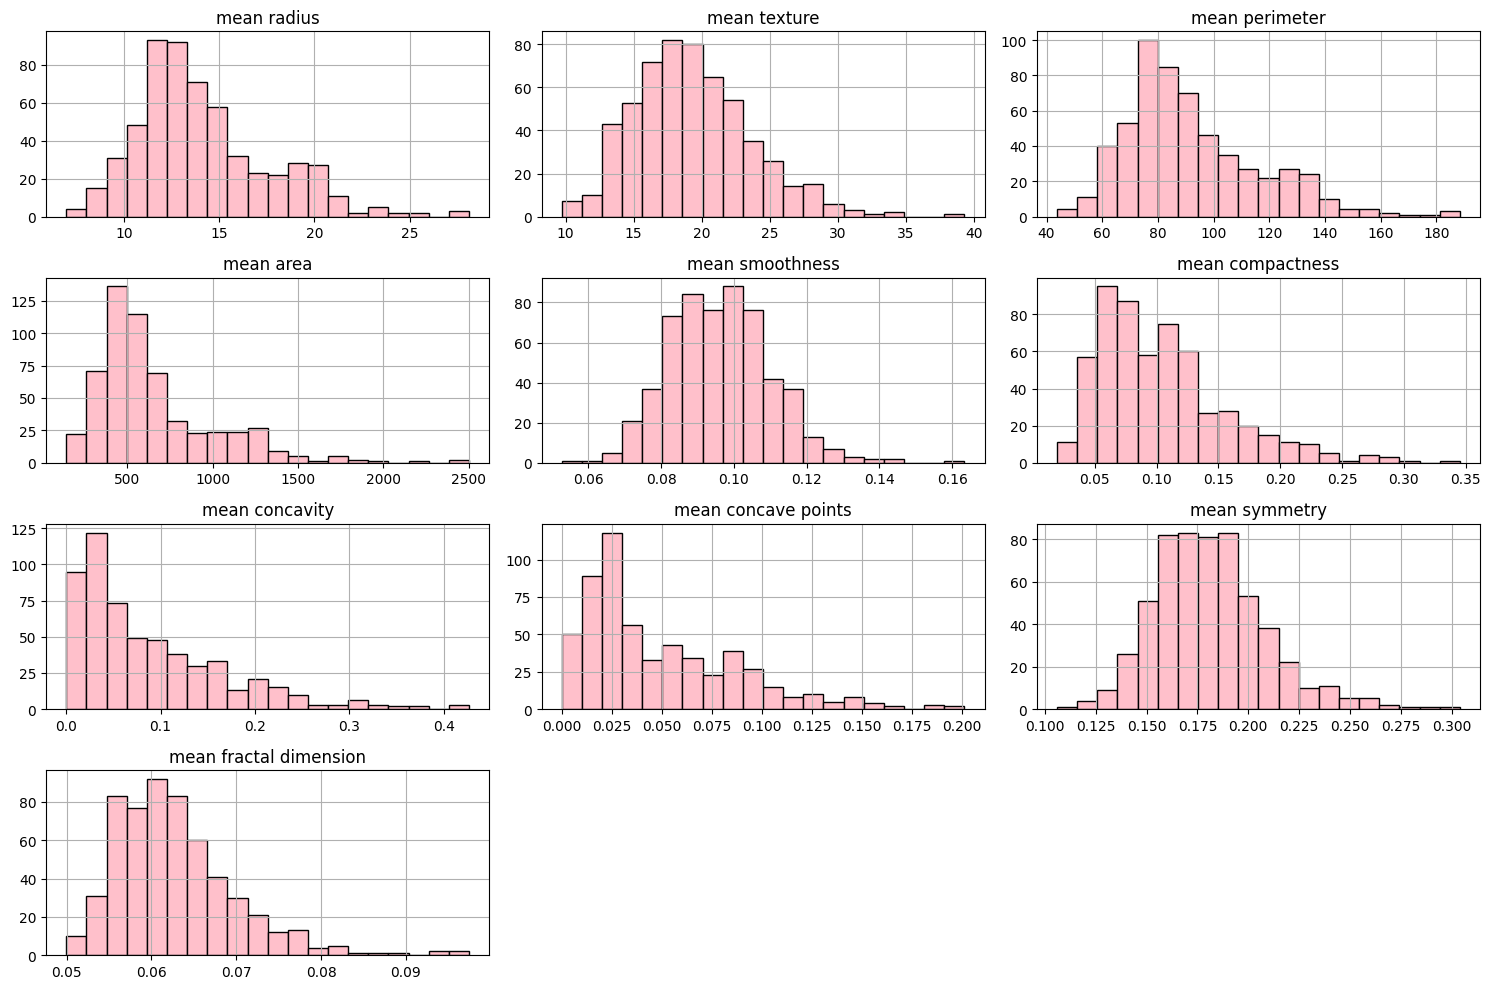

In [12]:
# TODO: histograms of the ten "mean" features (hint: df.filter(like="mean").hist)
...




df.filter(like="mean").hist(
    figsize=(15, 10),
    bins=20,
    edgecolor="black",
    color="pink"
)

import matplotlib.pyplot as plt
plt.tight_layout()
plt.show()



**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

<Figure size 600x400 with 0 Axes>

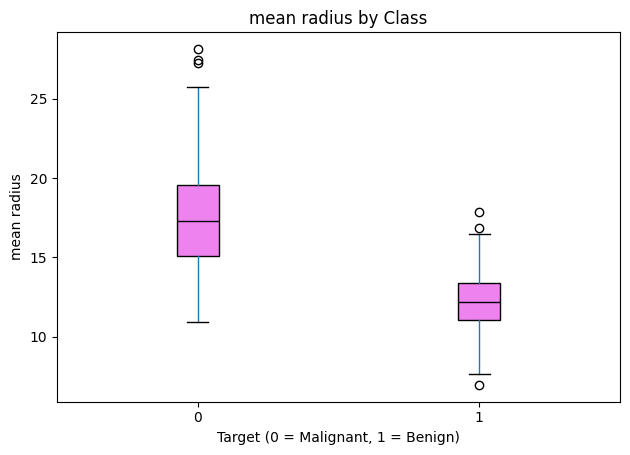

<Figure size 600x400 with 0 Axes>

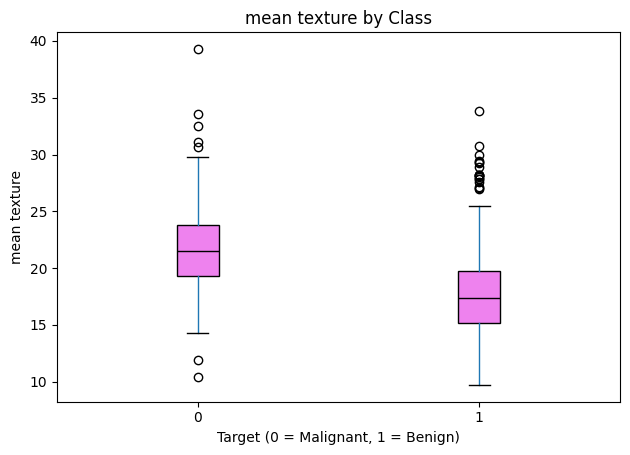

<Figure size 600x400 with 0 Axes>

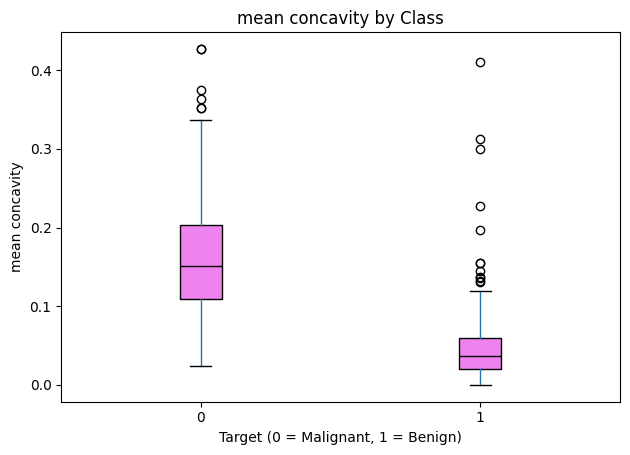

<Figure size 600x400 with 0 Axes>

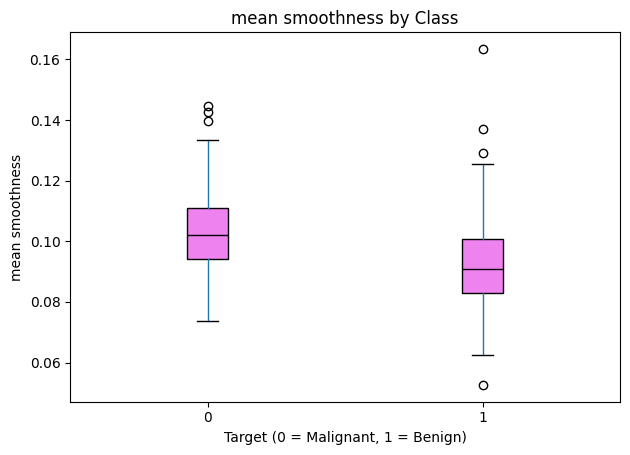

In [15]:
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]
# TODO: one box plot per feature, grouped by target
...

import matplotlib.pyplot as plt

features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]

# Create one box plot per feature, grouped by target
for feature in features:
    plt.figure(figsize=(6, 4))

    df.boxplot(
        column=feature,
        by="target",
        grid=False,
        patch_artist=True,
        boxprops=dict(facecolor="violet"),
        medianprops=dict(color="black")
    )

    plt.title(feature + " by Class")
    plt.suptitle("")
    plt.xlabel("Target (0 = Malignant, 1 = Benign)")
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()


**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

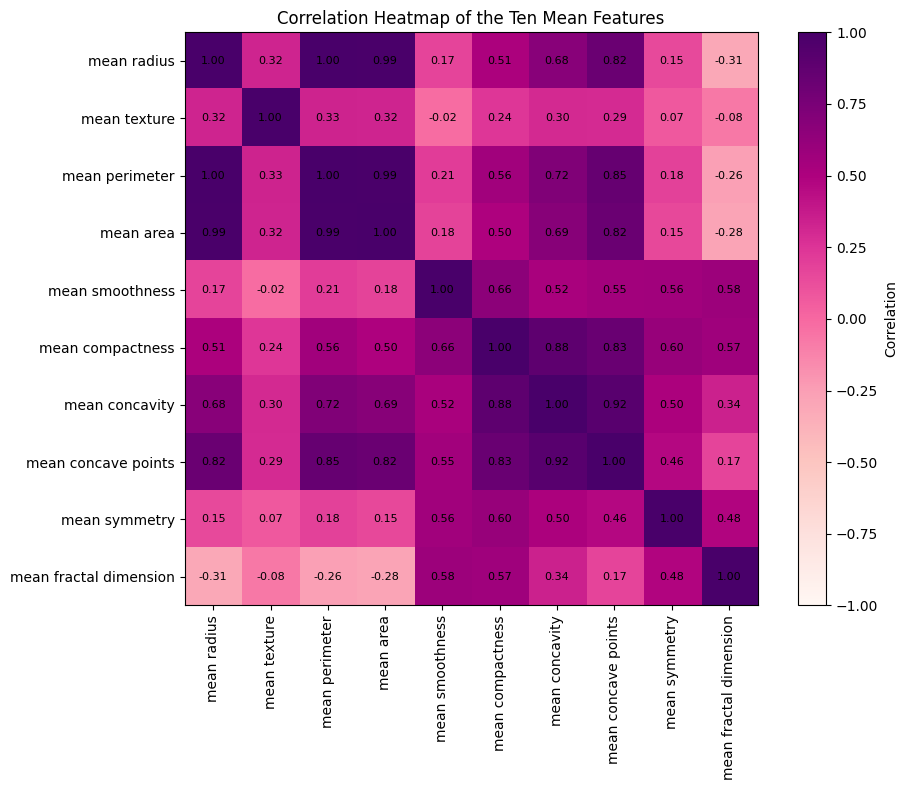

In [16]:
# TODO: correlation matrix of the "mean" features drawn with imshow
...

# Correlation matrix of the "mean" features drawn with imshow
import matplotlib.pyplot as plt
import numpy as np

mean_features = df.filter(like="mean")
corr_matrix = mean_features.corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr_matrix, cmap="RdPu", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")
plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=90)
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)

# Display correlation values
for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        plt.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}",
                 ha="center", va="center", fontsize=8)

plt.title("Correlation Heatmap of the Ten Mean Features")
plt.tight_layout()
plt.show()


**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

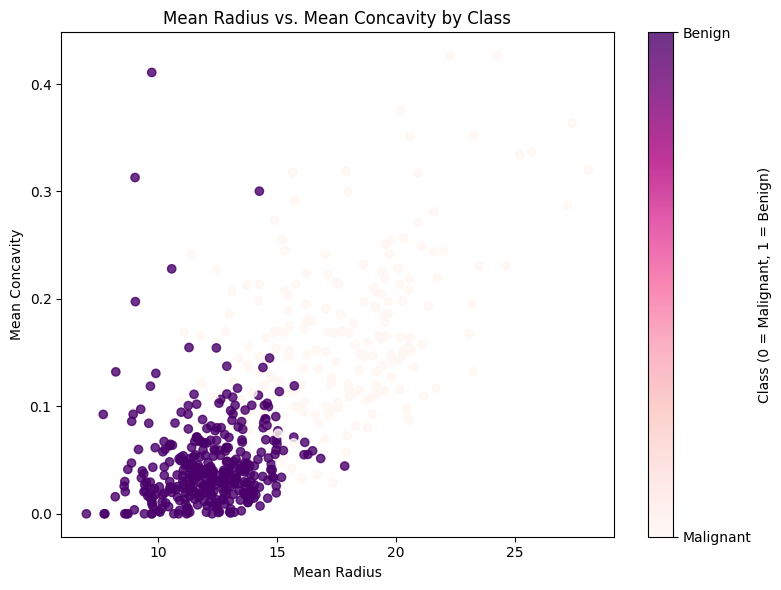

In [17]:
# TODO: coloured scatter plot with axis labels and a colourbar
...

import matplotlib.pyplot as plt

# Scatter plot colored by class
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    df["mean radius"],
    df["mean concavity"],
    c=df["target"],
    cmap="RdPu",
    alpha=0.8
)

plt.xlabel("Mean Radius")
plt.ylabel("Mean Concavity")
plt.title("Mean Radius vs. Mean Concavity by Class")

# Add a colorbar to identify the classes
cbar = plt.colorbar(scatter)
cbar.set_label("Class (0 = Malignant, 1 = Benign)")
cbar.set_ticks([0, 1])
cbar.set_ticklabels(["Malignant", "Benign"])

plt.tight_layout()
plt.show()


✏️ **Question B.10.** Which features appear redundant, and which separate the classes most clearly?

> **Your answer:** Mean radius , mean perimeter and the mean area seem the measure related aspects of tumor size. mean radius and mean concavity appears to seperate malignant and benign cases most clearly because malignant tumores generally gave larger sizes and more irregular shapres. soe values overlap between the classes so using several features helps improve prediction accuracy

---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [18]:
# TODO: total missing values and duplicated rows
...


print("Total missing values:", df.isnull().sum().sum())

print("Duplicated rows:", df.duplicated().sum())

X = df.drop(columns="target")
y = df["target"]


Total missing values: 0
Duplicated rows: 0


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [19]:
# TODO: IQR outlier count per feature
...


# IQR
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outlier_counts = ((X < lower) | (X > upper)).sum()


display(outlier_counts.sort_values(ascending=False).head(10))


,0
area error,65
radius error,38
perimeter error,38
worst area,35
smoothness error,30
fractal dimension error,28
compactness error,28
symmetry error,27
mean area,25
worst fractal dimension,24


✏️ **Question C.3.** Would you delete the outlying rows? Justify your decision.

> **Your answer:** No, I would not delete outliers because they may represent real tumor characteristics. I would keep valid values to avoid losing important information for predicting breast cancer.

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [20]:
# TODO: upper-triangle of the absolute correlation matrix, then columns above 0.95
...


corr = X.corr().abs()
upper = corr.where(
    __import__("numpy").triu(
        __import__("numpy").ones(corr.shape), k=1
    ).astype(bool)
)


high_corr = [
    col for col in upper.columns
    if (upper[col] > 0.95).any()
]

print("Highly correlated features:", high_corr)


Highly correlated features: ['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area']


**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [21]:
# TODO: fit SelectKBest(f_classif, k=10) and build a sorted Series of scores
...

from sklearn.feature_selection import SelectKBest, f_classif
import pandas as pd

selector = SelectKBest(score_func=f_classif, k=10)
selector.fit(X, y)

scores = pd.Series(
    selector.scores_,
    index=X.columns
).sort_values(ascending=False)

print("Top 10 features:")
display(scores.head(10))


Top 10 features:


,0
worst concave points,964.385393
worst perimeter,897.944219
mean concave points,861.676020
worst radius,860.781707
mean perimeter,697.235272
worst area,661.600206
mean radius,646.981021
mean area,573.060747
mean concavity,533.793126
worst concavity,436.691939


**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [22]:
# TODO: RFE(LogisticRegression, n_features_to_select=10) on standardised X; store names in rfe_features
...

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

rfe = RFE(
    estimator=LogisticRegression(max_iter=5000),
    n_features_to_select=10
)
rfe.fit(X_scaled, y)

rfe_features = list(X.columns[rfe.support_])

print("Selected RFE features:")
print(rfe_features)


Selected RFE features:
['mean concave points', 'radius error', 'area error', 'compactness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

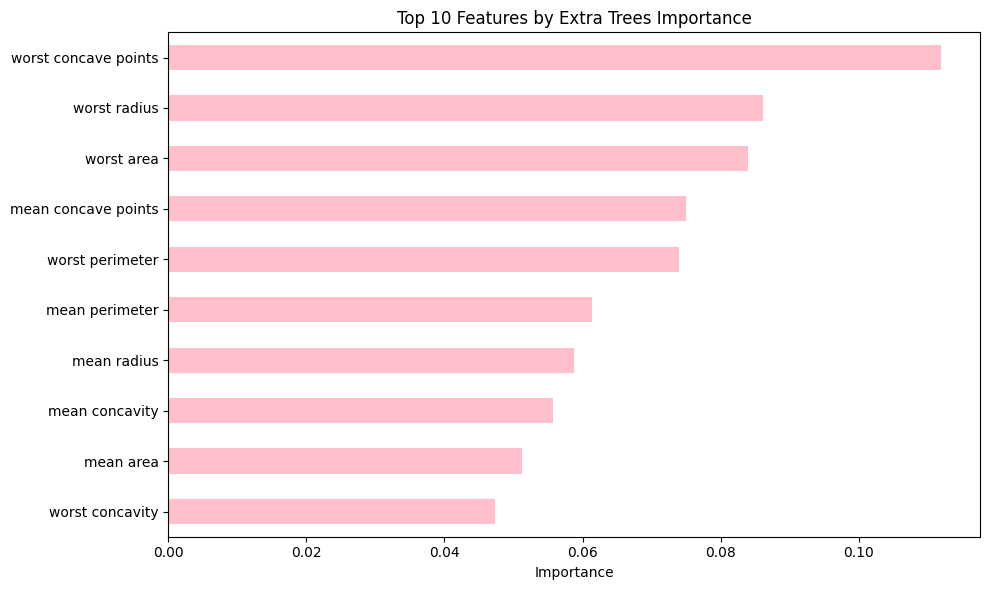

In [23]:
# TODO: fit ExtraTrees (200 trees, random_state=7), store importances in imp, plot barh of top 10
...

from sklearn.ensemble import ExtraTreesClassifier
import matplotlib.pyplot as plt

model = ExtraTreesClassifier(n_estimators=200, random_state=7)
model.fit(X, y)

imp = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
imp.head(10).sort_values().plot(kind="barh", color="pink")
plt.title("Top 10 Features by Extra Trees Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [25]:
# TODO: vote across the three methods
...




kbest_features = set(scores.head(10).index)
rfe_set = set(rfe_features)
extra_trees_features = set(imp.head(10).index)

selected = [
    feature for feature in X.columns
    if (
        int(feature in kbest_features)
        + int(feature in rfe_set)
        + int(feature in extra_trees_features)
    ) >= 2
]

print("Final selected features:")
print(selected)
print("Number of selected features:", len(selected))



Final selected features:
['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']
Number of selected features: 10


> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [27]:
# TODO: train_test_split with stratify=y
...


from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=7,
    stratify=y
)

print(X_train.shape, X_test.shape)


(455, 30) (114, 30)


**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [28]:
# TODO: fit both scalers on X_train and print the verifying statistics
...

from sklearn.preprocessing import StandardScaler, MinMaxScaler


standard_scaler = StandardScaler()
X_train_standard = standard_scaler.fit_transform(X_train)

minmax_scaler = MinMaxScaler()
X_train_minmax = minmax_scaler.fit_transform(X_train)


print("StandardScaler:")
print("Mean:", X_train_standard[:, :4].mean(axis=0))
print("Standard deviation:", X_train_standard[:, :4].std(axis=0))

print("\nMinMaxScaler:")
print("Minimum:", X_train_minmax[:, :4].min(axis=0))
print("Maximum:", X_train_minmax[:, :4].max(axis=0))


StandardScaler:
Mean: [ 9.36979432e-17 -3.74791773e-16 -5.79756023e-16 -3.27942801e-16]
Standard deviation: [1. 1. 1. 1.]

MinMaxScaler:
Minimum: [0. 0. 0. 0.]
Maximum: [1. 1. 1. 1.]


**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

In [29]:
# TODO: fit PCA on standardised training data and use the cumulative explained variance
...

from sklearn.decomposition import PCA
import numpy as np

pca = PCA()
pca.fit(X_train_standard)

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
n_components = np.argmax(cumulative_variance >= 0.95) + 1

print("Components needed for 95% variance:", n_components)
print("Cumulative explained variance:", cumulative_variance[n_components - 1])


Components needed for 95% variance: 10
Cumulative explained variance: 0.9560067676671444


---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [38]:


from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Define the six candidate models
models = {
    "LR": LogisticRegression(max_iter=5000),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=7),
    "NB": GaussianNB(),
    "SVM": SVC()
}

print("Six candidate models defined:")
print(list(models.keys()))


Six candidate models defined:
['LR', 'LDA', 'KNN', 'CART', 'NB', 'SVM']


**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [40]:

# Run spot-check on all features: raw and scaled
raw_results = spot_check(models, X_train, scale=False)
scaled_results = spot_check(models, X_train, scale=True)

# Build a DataFrame with mean accuracies
summary = pd.DataFrame({
    "raw": {name: scores.mean() for name, scores in raw_results.items()},
    "scaled": {name: scores.mean() for name, scores in scaled_results.items()}
})

display(summary)



,raw,scaled
LR,0.953768,0.982319
LDA,0.947246,0.947246
KNN,0.922947,0.964928
CART,0.927633,0.927633
NB,0.934058,0.932029
SVM,0.898696,0.975797


✏️ **Question D.3.** Which models benefit from scaling, and why?

> **Your answer:** KNN, SVM, and Logistic Regression benefit from scaling because they are sensitive to feature ranges. Decision Trees and Naive Bayes generally do not need scaling.

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [41]:
# TODO: spot_check on X_train[selected] and compare against the all-features scaled results
...

selected_results = spot_check(models, X_train[selected], scale=True)

selected_summary = pd.DataFrame({
    "All Features (Scaled)": {
        name: scores.mean() for name, scores in scaled_results.items()
    },
    "Selected Features (Scaled)": {
        name: scores.mean() for name, scores in selected_results.items()
    }
})

display(selected_summary)

,All Features (Scaled),Selected Features (Scaled)
LR,0.982319,0.960435
LDA,0.947246,0.942995
KNN,0.964928,0.942802
CART,0.927633,0.921014
NB,0.932029,0.951691
SVM,0.975797,0.953865


**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

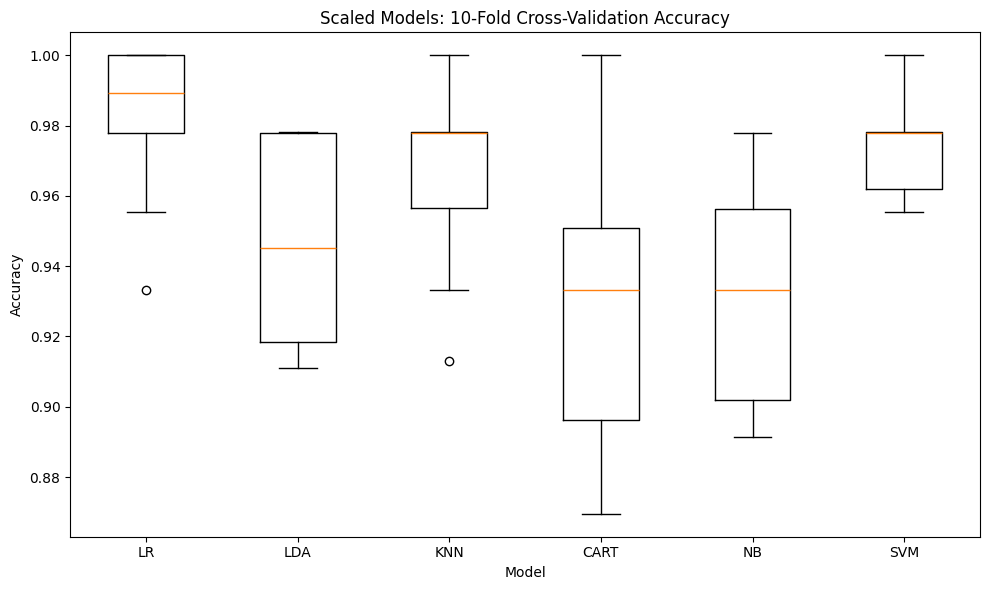

In [42]:
# TODO: box plot of the 10 fold scores per model
...
# Box plot of the 10-fold scores per model
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.boxplot(
    [scaled_results[name] for name in scaled_results],
    labels=list(scaled_results.keys())
)
plt.title("Scaled Models: 10-Fold Cross-Validation Accuracy")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.tight_layout()
plt.show()

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [43]:
# TODO: cross_validate with a scoring dict including make_scorer(recall_score, pos_label=0)
...
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, recall_score, roc_auc_score

# Choose the best scaled model based on the previous results
best_name = summary["scaled"].idxmax()
best_model = models[best_name]

scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "recall_malignant": make_scorer(recall_score, pos_label=0)
}

steps = [
    ("scale", StandardScaler()),
    ("model", best_model)
]

cv_results = cross_validate(
    Pipeline(steps),
    X_train,
    y_train,
    cv=kfold,
    scoring=scoring
)

results_df = pd.DataFrame({
    metric: cv_results[f"test_{metric}"]
    for metric in scoring
})

display(results_df.mean().to_frame("Mean Score"))

,Mean Score
accuracy,0.982319
roc_auc,0.992169
recall_malignant,0.964706


---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [44]:
# TODO: grid search over C=[0.1,1,10,100], gamma=["scale",0.001,0.01,0.1], kernel=["rbf","linear"]
...

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC())
])

param_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.001, 0.01, 0.1],
    "model__kernel": ["rbf", "linear"]
}

grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=kfold,
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best cross-validation accuracy:", grid.best_score_)

Best parameters: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best cross-validation accuracy: 0.9801932367149758


**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [45]:
# TODO: grid over n_neighbors=[3,5,7,9,11,15,21] and weights=["uniform","distance"]
...
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

pipeline_knn = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier())
])

param_grid_knn = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights": ["uniform", "distance"]
}

grid_knn = GridSearchCV(
    pipeline_knn,
    param_grid_knn,
    cv=kfold,
    scoring="accuracy",
    n_jobs=-1
)

grid_knn.fit(X_train, y_train)

print("Best parameters:", grid_knn.best_params_)
print("Best cross-validation accuracy:", grid_knn.best_score_)

Best parameters: {'model__n_neighbors': 3, 'model__weights': 'uniform'}
Best cross-validation accuracy: 0.9692753623188406


### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [46]:
# TODO: dictionary ensembles, score with spot_check(scale=False), then a hard VotingClassifier
...
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import pandas as pd


ensembles = {
    "Random Forest": RandomForestClassifier(random_state=7),
    "Extra Trees": ExtraTreesClassifier(random_state=7),
    "Gradient Boosting": GradientBoostingClassifier(random_state=7),
    "AdaBoost": AdaBoostClassifier(random_state=7)
}


ensemble_results = spot_check(ensembles, X_train, scale=False)

ensemble_summary = pd.DataFrame({
    name: scores.mean()
    for name, scores in ensemble_results.items()
}, index=["Mean Accuracy"]).T

display(ensemble_summary)


voting = VotingClassifier(
    estimators=[
        ("svm", grid.best_estimator_),
        ("knn", grid_knn.best_estimator_),
        ("rf", RandomForestClassifier(random_state=7))
    ],
    voting="hard"
)


voting_scores = cross_val_score(
    voting,
    X_train,
    y_train,
    cv=kfold,
    scoring="accuracy"
)

print("Voting Ensemble Mean Accuracy:", voting_scores.mean())
print("Voting Ensemble Standard Deviation:", voting_scores.std())


,Mean Accuracy
Random Forest,0.969130
Extra Trees,0.973575
Gradient Boosting,0.966957
AdaBoost,0.962560


Voting Ensemble Mean Accuracy: 0.9780676328502416
Voting Ensemble Standard Deviation: 0.025805603911037964


**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [47]:
# TODO: leaderboard Series
...

leaderboard = pd.Series({
    "Tuned SVM": grid.best_score_,
    "Tuned KNN": grid_knn.best_score_,
    "Random Forest": ensemble_results["Random Forest"].mean(),
    "Extra Trees": ensemble_results["Extra Trees"].mean(),
    "Gradient Boosting": ensemble_results["Gradient Boosting"].mean(),
    "AdaBoost": ensemble_results["AdaBoost"].mean(),
    "Voting Ensemble": voting_scores.mean()
}).sort_values(ascending=False)

display(leaderboard)

,0
Tuned SVM,0.980193
Voting Ensemble,0.978068
Extra Trees,0.973575
Tuned KNN,0.969275
Random Forest,0.969130
Gradient Boosting,0.966957
AdaBoost,0.962560


### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

Winning model: Tuned SVM
Test Accuracy: 0.9649122807017544

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.95      0.95      0.95        42
      Benign       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



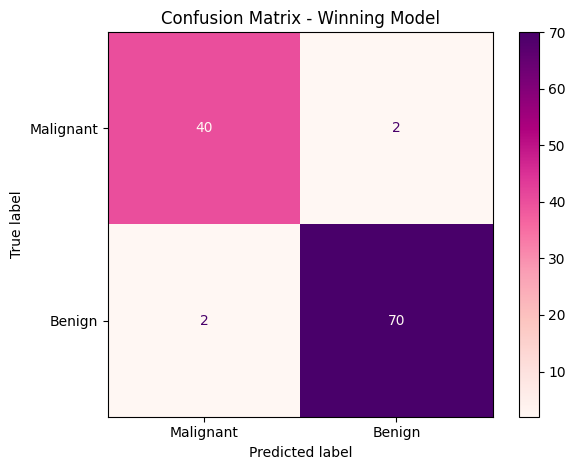

In [48]:
# TODO: pick the leaderboard winner, fit on train, predict test, print metrics, plot confusion matrix
...

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Pick the leaderboard winner
winner_name = leaderboard.index[0]
print("Winning model:", winner_name)

# Select the winning model
if winner_name == "Tuned SVM":
    winner = grid.best_estimator_
elif winner_name == "Tuned KNN":
    winner = grid_knn.best_estimator_
elif winner_name == "Voting Ensemble":
    winner = voting
else:
    winner = ensembles[winner_name]

# Fit on the full training set
winner.fit(X_train, y_train)

# Predict the test set (final evaluation)
y_pred = winner.predict(X_test)

# Print accuracy and classification report
print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Malignant", "Benign"]
))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant", "Benign"]
)
display.plot(cmap="RdPu")
plt.title("Confusion Matrix - Winning Model")
plt.tight_layout()
plt.show()

**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [50]:
# TODO: joblib.dump, joblib.load, compare first 5 predictions with y_test
...
import joblib
import numpy as np

# Save the trained model
joblib.dump(winner, "breast_cancer_model.joblib")

# Reload the saved model
loaded_model = joblib.load("breast_cancer_model.joblib")

# Compare the first 5 predictions with y_test
original_predictions = winner.predict(X_test.iloc[:5])
loaded_predictions = loaded_model.predict(X_test.iloc[:5])

print("Original predictions:", original_predictions)
print("Reloaded predictions:", loaded_predictions)
print("Actual values:", y_test.iloc[:5].to_numpy())

print("Predictions match:", np.array_equal(original_predictions, loaded_predictions))


Original predictions: [0 0 1 0 1]
Reloaded predictions: [0 0 1 0 1]
Actual values: [0 0 1 0 1]
Predictions match: True


---
## Reflection Questions
✏️ Answer in a short paragraph each.

1. **Leakage.** Feature selection in Part C used the whole dataset. Explain why this can inflate CV scores and how you would fix it using a `Pipeline`.
2. **Metric choice.** Which metric would you report to a clinician, and why is accuracy alone insufficient?
3. **Model choice.** If two models differ by 0.3% in CV accuracy, how would you decide between them? (Think variance across folds, interpretability, training cost.)
4. **Generalization.** How would your conclusions change with a much smaller or much more imbalanced dataset?
5. **Extension.** Repeat the workbook with a dataset of your choice (e.g., loaded from an ARFF file) and note which steps change.

**Submission checklist:** all `TODO`s completed · all cells run top to bottom · written answers filled in · final test accuracy reported once.

In [ ]:
# 1. Leakage. Feature selection using the whole dataset can cause data leakage because information from the test or validation folds influences which features are selected. This can make cross-validation scores look better than they really are. To fix this, I would use a Pipeline that performs feature selection separately inside each training fold.

2. Metric choice. I would report recall for the malignant class, along with precision, F1-score, and accuracy. Recall is important because it measures how many actual malignant cases the model correctly identifies. Accuracy alone is insufficient because it can hide missed cancer cases.

3. Model choice. If two models differ by only 0.3% in cross-validation accuracy, I would compare their score variation across folds and choose the more consistent model. I would also consider interpretability and training time, preferring the simpler model if its performance is similar.

4. Generalization. With a much smaller dataset, I would use careful cross-validation because the results may vary more between splits. With a highly imbalanced dataset, I would focus more on recall, precision, F1-score, and ROC-AUC instead of relying mainly on accuracy. I would also use stratified splitting to preserve class proportions.

5. Extension. If I repeated the workbook using another dataset, such as one loaded from an ARFF file, I would change the data-loading code, target column, and possibly the preprocessing steps. I would repeat data exploration, feature selection, model comparison, tuning, and evaluation while keeping the test set separate until the final evaluation.